# TP 3 : Classification non supervisée (ou *clustering*)

L'objectif de ce TP consiste à implémenter une méthode à noyau appelée classification non supervisée et de tester d'autres méthodes non supervisées via la librarie *scikit-learn* sur des benchmarks de classification non supervisée.

In [ ]:
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
import sklearn

In [ ]:
from google.colab import files

uploaded1 = files.upload()

In [ ]:
from google.colab import files

uploaded2 = files.upload()

Saving Smiley.txt to Smiley.txt


## Classification spectrale

Parmi les méthodes de partitionnement non supervisé, les méthodes à noyaux reposent sur le même principe : elles utilisent des relations d'adjacence (d'affinité) entre tous les couples de points sans a priori sur les formes des classes. Nous nous concentrons sur l'algorithme de classification spectrale décrit ci-dessous, très simple à implémenter. La mesure d'affinité utilisée est l'affinité gaussienne qui dépend d'un paramètre noté $\sigma$.


On dispose d'un ensemble  de données $S=\{x_i\}_{i=1,..,n}\in \mathbb{R}^p$ composé de $n$ points de dimension $p$ et d'un nombre de classes, noté $k$, à obtenir. La méthode de classification spectrale  consiste à extraire les vecteurs propres associés aux plus grandes valeurs propres d'une matrice d'affinité normalisée. Ces vecteurs propres constituent ensuite un espace de dimension réduite dans lequel les données transformées seront linéairement séparables.  


**Input :** Ensemble de données $S \in \mathbb{R}^{n\times p}$, nombre de clusters $k$ et le paramètre $\sigma$.

1. Construction de la matrice affinité $A\in \mathbb{R}^{n \times n}$ définie par :
$$A_{ij}=\begin{cases}
exp(-\|x_i-x_j\|^2/2\sigma^2) \text{ si } i\neq j\\
0 \text{ sinon.}
\end{cases}
$$
2. Construction de la matrice normalisée $L=D^{-1}A$ où $D$ matrice diagonale définie par :
   $$D_{ii}=\sum_{j=1}^n A_{ij}.$$
3. Construction de de la matrice $V=[v_1v_2..v_k]\in \mathbb{R}^{n\times k}$ formée à partir des $k$ plus grands vecteurs propres $v_i,\ i=\{1,..k\}$ de L.
4. Construction de la matrice $Y$ formée en normalisant les lignes de $V$ :
   $$Y_{ij}=\frac{V_{ij}}{\sqrt{\sum_{j}V_{ij}^2}}.$$
5. Traiter chaque ligne de $Y$ comme un point de $\mathbb{R}^k$ et les classer en $k$ clusters via la méthode K-means.
6. Assigner le point original $x_i$ au cluster $j$ si et seulement si la ligne $i$ de la matrice $Y$ est assignée au cluster $j$.


### Travail demandé

- Ecrire la fonction **classification_spectrale** implantant l'algorithme 1. Cette fonction en entrée les données Input de l'algorithme.
- Tester la fonction sur les deux jeux de données (*Aggregation.txt* et *Smiley.txt*) mis à disposition et tester différentes valeurs de paramètres $\sigma$. Les résultats sont-ils similaires ?
- Comparer, en utilisant la librairie *scikit-learn*, les résultats de cette méthode avec une autre méthode non supervisée comme Kmeans, classification hiérarchique...


### Fonctions python utiles
- exp (numpy)
- norm (linalg)
- inv (linalg)
- eig (linalg)
- kmeans (sklearn)

In [ ]:
def classification_spectrale(Data,k,sigma):
    Data=np.asarray(Data)
    k=int(k)
    n = Data.shape[0]

    # construction de la matrice affinité
    A = np.zeros((Data.shape[0], Data.shape[0]))
    for i in range(Data.shape[0]):
      for j in range(Data.shape[0]):
        if i != j:
          A[i,j] = np.exp(-np.linalg.norm(Data[i]-Data[j])**2/(2*sigma**2))
        else:
          A[i,j] = 0

    # Normalisation de la matrice affinité
    D = np.zeros((Data.shape[0], Data.shape[0]))
    for i in range(Data.shape[0]):
      D[i,i] = np.sum(A[i,:])

    L = np.dot(np.linalg.inv(D), A)

    # Calcul des vecteurs propres de L
    valP, vecP = np.linalg.eig(L)

    # Extraction des k + grands vecteurs propres
    idx = valP.argsort()[-k:][::-1]
    vecPchoix = vecP[:, idx]

    # Normalisation des lignes de V
    Y = vecPchoix / np.linalg.norm(vecPchoix, axis=1)[:, np.newaxis]

    #Kmeans sur l'espace spectral
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10) # Added n_init for KMeans
    PartitionSC=kmeans.fit_predict(Y)

    return PartitionSC



```
def classification_spectrale(Data,k,sigma):
    Data=np.asarray(Data)
    k=int(k)
    
    # construction de la matrice affinité
    A = np.zeros(Data.shape[0], Data.shape[1])
    for i in range(Data.shape[0]):
      for j in range(Data.shape[0]):
        if i != j:
          A[i,j] = np.exp(-np.linalg.norm(Data[i]-Data[j])**2/(2*sigma**2))
        else:
          A[i,j] = 0
    
    # Normalisation de la matrice affinité
    D = np.zeros(Data.shape[0], Data.shape[0])
    for i in range(Data.shape[0]):
      D[i,i] = np.sum(A[i,:])

    L = np.dot(np.linalg.inv(D), A)
    
    # Calcul des vecteurs propres de L
    valP, vecP = np.linalg.eig(L)
    
    #Extraction des k + grands vecteurs propres
    vecPchoix =
    
    # Normalisation des lignes de V
    # A COMPLETER    
    
    #Kmeans sur l'espace spectral
    PartitionSC=np.zeros((n,1))
    # A COMPLETER
    
    return PartitionSC
```


##  Test sur des benchmark de clustering

Dimension du dataset : (788, 2)
Nombre de classes à trouver : 7.0


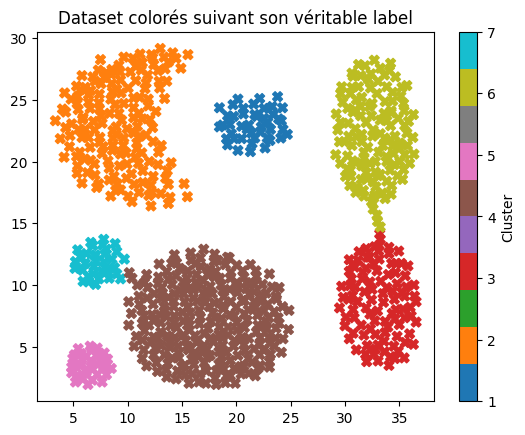

In [ ]:
# Chargement du premier dataset
Data1=np.genfromtxt('Aggregation.txt')

# Stockage des coordonnées géomtriques 2D
Dataset1=Data1[:,:2]
print('Dimension du dataset :', Dataset1.shape)

# Stockage du label associé à chaque point
LabelData1=Data1[:,2]
print('Nombre de classes à trouver :', max(LabelData1))

# Représentation des données et de leur label
plt.scatter(Dataset1[:,0],Dataset1[:,1],c=LabelData1, marker='X',cmap='tab10',s=50)
plt.colorbar(label="Cluster")
plt.title("Dataset colorés suivant son véritable label")
plt.show()

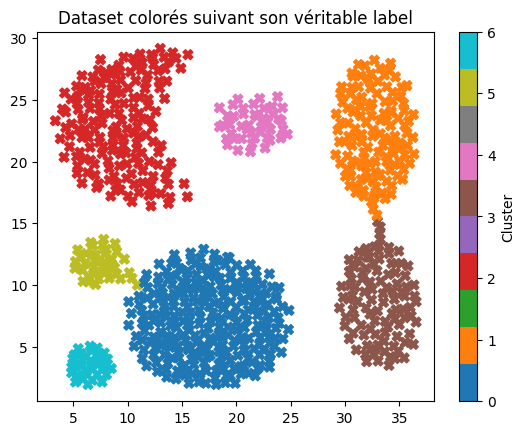

In [ ]:
# Tester la classification spectrale sur ce dataset
partition = classification_spectrale(Dataset1,7,1)

# Représentation des données et de leur label
plt.scatter(Dataset1[:,0],Dataset1[:,1],c=partition, marker='X',cmap='tab10',s=50)
plt.colorbar(label="Cluster")
plt.title("Dataset colorés suivant son véritable label")
plt.show()

Dimension du dataset : (788, 2)
Nombre de classes à trouver : 5.0


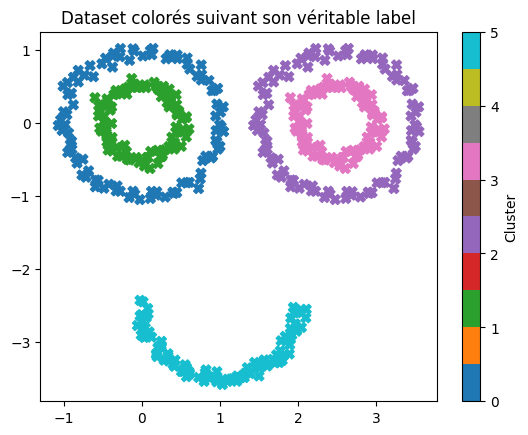

In [ ]:
# Chargement du second dataset
Data2=np.genfromtxt('Smiley.txt')


# Stockage des coordonnées géomtriques 2D
Dataset2=Data2[:,:2]
print('Dimension du dataset :', Dataset1.shape)

# Stockage du label associé à chaque point
LabelData2=Data2[:,2]
print('Nombre de classes à trouver :', max(LabelData2))

# Représentation des données et de leur label
plt.scatter(Dataset2[:,0],Dataset2[:,1],c=LabelData2, marker='X',cmap='tab10',s=50)
plt.colorbar(label="Cluster")
plt.title("Dataset colorés suivant son véritable label")
plt.show()

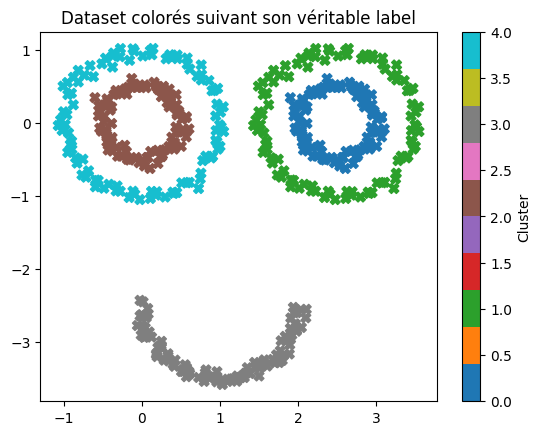

In [ ]:
# Tester la classification spectrale sur ce dataset
partition2 = classification_spectrale(Dataset2,5,0.1)

# Représentation des données et de leur label
plt.scatter(Dataset2[:,0],Dataset2[:,1],c=partition2, marker='X',cmap='tab10',s=50)
plt.colorbar(label="Cluster")
plt.title("Dataset colorés suivant son véritable label")
plt.show()

## Comparaison avec une autre méthode de clustering

on pourra utiliser le lien suivant où sont recensées toutes les méthodes de clustering de *scikit-learn* :
https://scikit-learn.org/stable/modules/clustering.html